# Examination Result and Academic Performance Analysis Using Python

**ITW III Course Project**

This notebook analyses student examination scores in mathematics, reading, and writing. It calculates basic statistics, pass percentages, grade distributions, compares subjects, and visualizes the results.

**Libraries:** Pandas, NumPy, Matplotlib  
**Dataset:** Students Performance in Exams (Kaggle)

For this project, a score of 40 or above out of 100 is treated as a pass. This is an assumption for analysis and can be changed if needed.

## 1. Import the libraries

We use Pandas to work with tabular data, NumPy for calculations, and Matplotlib to create charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load the dataset

Download the CSV file from the Kaggle dataset page and place it in the same folder as this notebook.`StudentsPerformance.csv`.

Dataset: https://www.kaggle.com/datasets/spscientist/students-performance-in-exams

In [2]:
file_name = "StudentsPerformance.csv"

df = pd.read_csv(file_name)

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)

First five rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Dataset shape: (1000, 8)


## 3. Check and prepare the data

First, inspect the column names, data types, and missing values. The original dataset uses spaces in some column names, so we rename the score columns to make them easier to use in code.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

df = df.rename(columns={
    "math score": "Math",
    "reading score": "Reading",
    "writing score": "Writing"
})

subjects = ["Math", "Reading", "Writing"]

print("\nBasic information:")
df.info()

Column names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Missing values in each column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Basic information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   Math                  

## 4. Basic statistical analysis

Calculate the average, highest, and lowest marks for each subject. The table also includes the standard deviation, which gives an idea of how spread out the marks are.

In [4]:
subject_stats = df[subjects].agg(["mean", "max", "min", "std"]).T
subject_stats = subject_stats.rename(columns={
    "mean": "Average",
    "max": "Highest",
    "min": "Lowest",
    "std": "Standard Deviation"
})

display(subject_stats.round(2))

,Average,Highest,Lowest,Standard Deviation
Math,66.09,100.0,0.0,15.16
Reading,69.17,100.0,17.0,14.60
Writing,68.05,100.0,10.0,15.20


## 5. Pass percentage

For this analysis, marks of 40 or above are considered a pass. We calculate the number and percentage of students who passed each subject.

In [5]:
pass_mark = 40
pass_results = {}

for subject in subjects:
    passed = (df[subject] >= pass_mark).sum()
    total = len(df)
    pass_percentage = (passed / total) * 100

    pass_results[subject] = {
        "Students Passed": passed,
        "Students Failed": total - passed,
        "Pass Percentage": pass_percentage
    }

pass_df = pd.DataFrame(pass_results).T
display(pass_df.round(2))

,Students Passed,Students Failed,Pass Percentage
Math,960.0,40.0,96.0
Reading,974.0,26.0,97.4
Writing,968.0,32.0,96.8


## 6. Grade distribution

The following grade ranges are used for a simple comparison:
- A: 80–100
- B: 70–79
- C: 60–69
- D: 50–59
- E: 40–49
- F: Below 40

These are project-defined ranges, not an official grading scheme.

In [6]:
def get_grade(mark):
    if mark >= 80:
        return "A"
    elif mark >= 70:
        return "B"
    elif mark >= 60:
        return "C"
    elif mark >= 50:
        return "D"
    elif mark >= 40:
        return "E"
    else:
        return "F"

grade_counts = {}

for subject in subjects:
    grade_counts[subject] = df[subject].apply(get_grade).value_counts()

grade_df = pd.DataFrame(grade_counts).fillna(0).astype(int)
grade_df = grade_df.reindex(["A", "B", "C", "D", "E", "F"])

display(grade_df)

,Math,Reading,Writing
A,193,249,235
B,216,264,254
C,268,233,230
D,188,164,167
E,95,64,82
F,40,26,32


## 7. Compare average marks across subjects

A bar chart makes it easier to compare the average score in each subject.

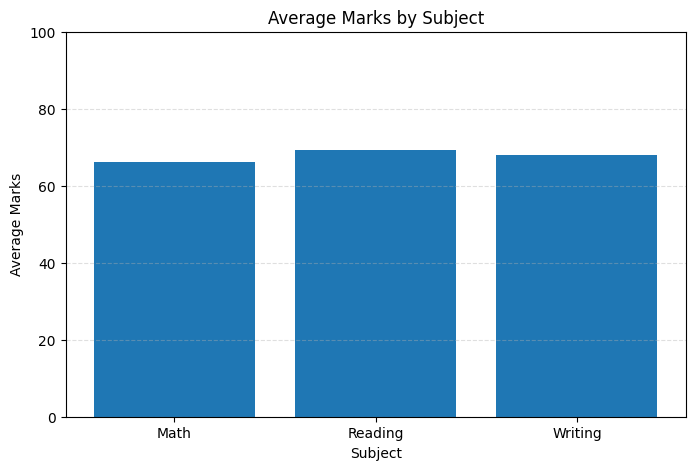

In [7]:
average_marks = df[subjects].mean()

plt.figure(figsize=(8, 5))
plt.bar(average_marks.index, average_marks.values)
plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

## 8. View score distributions

Histograms show how marks are spread across students in each subject.

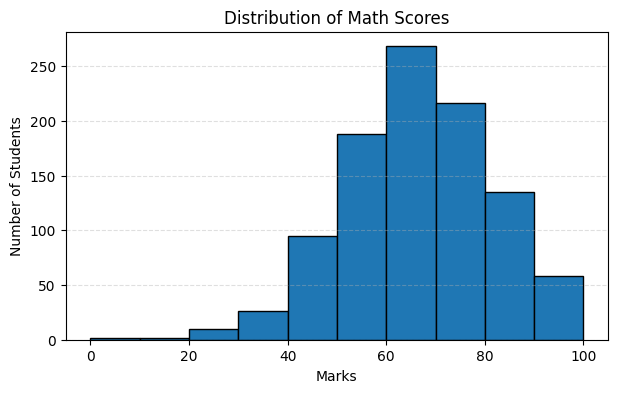

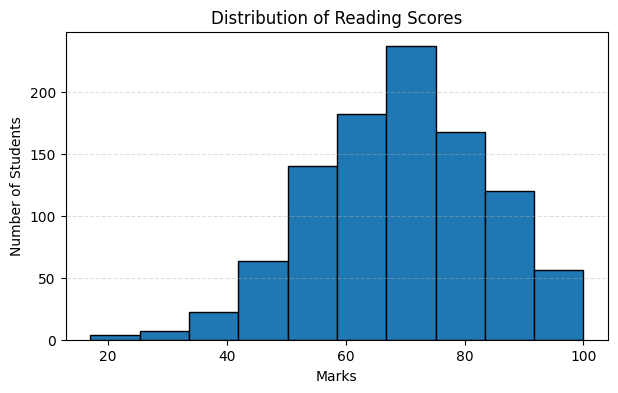

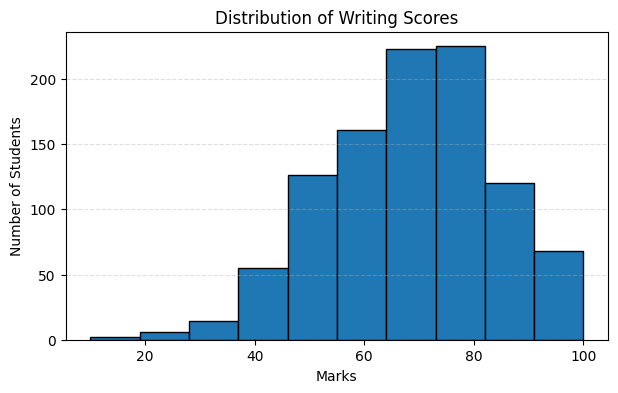

In [8]:
for subject in subjects:
    plt.figure(figsize=(7, 4))
    plt.hist(df[subject], bins=10, edgecolor="black")
    plt.title("Distribution of " + subject + " Scores")
    plt.xlabel("Marks")
    plt.ylabel("Number of Students")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.show()

## 9. Visualize pass and fail results

This chart compares the number of students who passed and failed each subject using the selected pass mark.

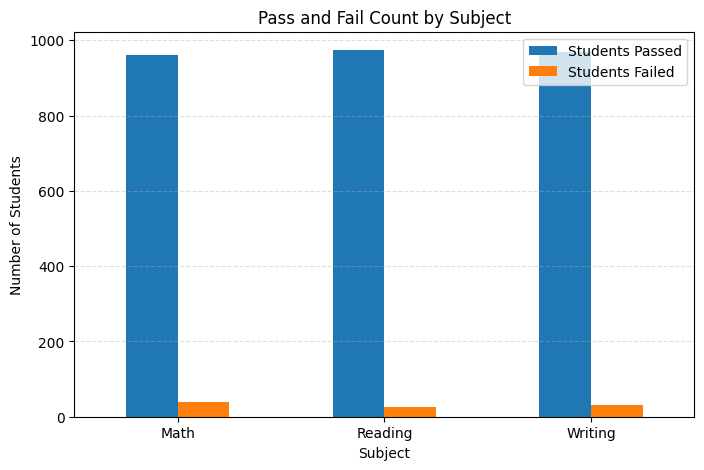

In [9]:
pass_counts = pass_df[["Students Passed", "Students Failed"]]

pass_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Pass and Fail Count by Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

## 10. Compare grade distributions

This chart shows the number of students in each grade for all three subjects.

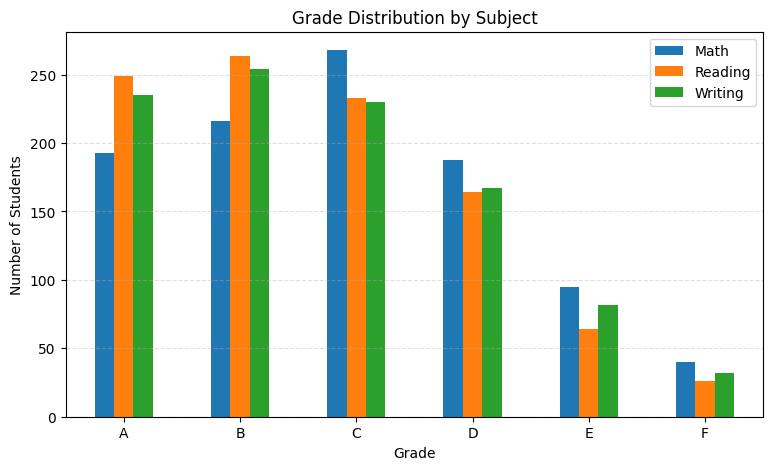

In [10]:
grade_df.plot(kind="bar", figsize=(9, 5))
plt.title("Grade Distribution by Subject")
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

## 11. Identify the subject with the lowest average

This section identifies which subject has the lowest average score. It can help highlight a subject that may need more attention, but it does not prove why students scored lower.

In [ ]:
lowest_subject = average_marks.idxmin()
lowest_average = average_marks.min()

print("Subject with the lowest average:", lowest_subject)
print("Average marks:", round(lowest_average, 2))

print("\nAverage marks in each subject:")
for subject, avg in average_marks.items():
    print(subject + ":", round(avg, 2))

## 12. Explore relationships between subject scores

Correlation measures how strongly two sets of scores vary together. Values closer to 1 indicate a stronger positive relationship. Correlation does not prove that one score causes another.

In [ ]:
score_correlation = df[subjects].corr()

display(score_correlation.round(2))

plt.figure(figsize=(6, 5))
plt.imshow(score_correlation, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(subjects)), subjects)
plt.yticks(range(len(subjects)), subjects)
plt.title("Correlation Between Subject Scores")

for i in range(len(subjects)):
    for j in range(len(subjects)):
        plt.text(j, i, f"{score_correlation.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.show()

## 13. Final summary

Generate a short summary from the calculated results. The values are filled in automatically from the dataset.

In [ ]:
print("EXAMINATION RESULT SUMMARY")
print("-" * 30)
print("Total students:", len(df))

for subject in subjects:
    print(
        f"{subject}: average = {df[subject].mean():.2f}, "
        f"pass percentage = {pass_df.loc[subject, 'Pass Percentage']:.2f}%"
    )

print(
    "\nThe subject with the lowest average score is",
    lowest_subject,
    f"({lowest_average:.2f} marks)."
)

## 14. Conclusion

This project used Python libraries to analyse examination scores and present the results through statistics and visualizations. It compared subject averages, pass percentages, grade distributions, score distributions, and relationships between subject scores.

The findings can help summarize class performance and identify subjects that may need further review. The results describe this dataset only and should not be treated as proof of the reasons behind student performance.